In [1]:
import os
import sys
sys.path.append("..")

In [2]:
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)

In [3]:
# Model for classical C51 on image data.

from dataclasses import dataclass, field
from flax import nnx
from qnrl.modules.serializable import SerializableModule

@dataclass(kw_only=True)
class DistQNetworkConv(SerializableModule):
    w: int # Image width.
    h: int # Image height.
    frame_stack: int # Number of frames that will be stacked together.
    din: int # Number of image feature dimensions (e.g., `din=3` for RGB image, `din=1` for greyscale image).
    num_actions: int
    num_atoms: int
    conv_douts: list[int] # List of convolutional output dimensions.
    conv_kernel_size: list[tuple[int,int]] # Msut be same length as `conv_douts`.
    conv_strides: list[tuple[int,int]] # Msut be same length as `conv_douts`.
    linear_douts: list[int] = field(default_factory=list) # List of linear layers applied after convolutions and before distribution projection.
    rngs_kwargs: dict[str, int]
    
    
    def __post_init__(self):
        self.reseed(self.rngs_kwargs)
    
    @staticmethod
    def compute_conv_output_shape(l_in, padding, dilation, kernel_size, stride):
        return int(jnp.floor((l_in + 2.*padding - dilation * (kernel_size - 1) - 1)/stride + 1))
    
    def reseed(self, rngs_kwargs: dict[str, int]):
        """Re-create model parameters using a dictionary of `nnx.Rngs` keyword arguments."""
        self.rngs_kwargs = rngs_kwargs
        rngs: nnx.Rngs = nnx.Rngs(**rngs_kwargs)
        
        
        # Convolutions.
        assert len(self.conv_douts) == len(self.conv_kernel_size) == len(self.conv_strides)
        dims = [self.din*self.frame_stack, *self.conv_douts]
        din_dout = list(zip(dims[:-1], dims[1:])) # (din, dout)
        self.convs = [
            nnx.Conv(in_features=in_features, out_features=out_features, kernel_size=self.conv_kernel_size[i], strides=self.conv_strides[i], padding="VALID", rngs=rngs)
            for i, (in_features, out_features) in enumerate(din_dout)
        ]
        # Compute image dimensions after each convolution.
        w, h = self.w, self.h
        for i in range(len(self.convs)):
            h = self.compute_conv_output_shape(h, padding=0, dilation=self.convs[i].input_dilation, kernel_size=self.conv_kernel_size[i][0], stride=self.conv_strides[i][0])
            w = self.compute_conv_output_shape(w, padding=0, dilation=self.convs[i].input_dilation, kernel_size=self.conv_kernel_size[i][1], stride=self.conv_strides[i][1])
        # Preserve output dimension of final convolution.
        final_conv_out_features = self.convs[-1].out_features
        
        # Organize dimensions so that the output of one is the input of another.
        dims = [final_conv_out_features*h*w, *self.linear_douts, self.num_actions * self.num_atoms]
        din_dout = list(zip(dims[:-1], dims[1:])) # (din, dout)
        self.linears = [
            nnx.Linear(in_features=in_features, out_features=out_features, rngs=rngs)
            for in_features, out_features in din_dout
        ]
    
    @nnx.jit
    def __call__(self, x): # (batch, frame_stack, w, h, din)
        # Ensure input shape with batch dimension (defaults to `batch=1`).
        x = jnp.asarray(x)
        x = x.reshape((-1, self.frame_stack, self.w, self.h, self.din,))
        
        # Convert to shape: (batch, w, h, din, frame_stack)
        x = jnp.transpose(x, (0, 2, 3, 4, 1))
        
        # Combine `frame_stack` and `din` into one feature dimension.
        x = x.reshape(*x.shape[:-2], -1)
        
        # Apply Conv+ReLU to all convolutions.
        for layer in self.convs:
            x = layer(x)
            x = nnx.relu(x)
        
        # Reshape to 2D (batch, feature).
        x = x.reshape((x.shape[0], -1))
        
        # Apply Linear+ReLU to all linears except last layer.
        for layer in self.linears[:-1]:
            x = layer(x)
            x = nnx.relu(x)
        
        # Generate return-atom distribution using last layer.
        x = self.linears[-1](x)
        x = x.reshape((-1, self.num_actions, self.num_atoms)) # (batch, action, atom)
        x = nnx.softmax(x, axis=-1) # Distribution over the atoms for every action.
        return x

In [4]:
from qnrl.environment import *
from qnrl.optimizer import *
from qnrl.algorithms.c51 import C51


# env = gym.make("ALE/Breakout-v5")
# env.unwrapped.get_action_meanings()


env_cfg = EnvConfig(env_id="ALE/Breakout-v5", extra_args=dict(frameskip=1, repeat_action_probability=0.0), max_episode_steps=10_000)
# 
# env_cfg = ResizeObservation(env=env_cfg, shape=(84,84))
# env_cfg = GrayscaleObservation(env=env_cfg, keep_dim=True)
# env_cfg = FrameStackObservation(env=env_cfg, stack_size=4)
# env_cfg = ScaleObservation(env=env_cfg, scale=255.0) # x/255.0
# 
env_cfg = AtariPreprocessing(env=env_cfg, noop_max=30, frame_skip=4, screen_size=84, terminal_on_life_loss=True, grayscale_obs=True, scale_obs=True)
env_cfg = FrameStackObservation(env=env_cfg, stack_size=4)
env_cfg = FireResetEnvWrapper(env=env_cfg)
# 
z_min = -10
z_max = 10


seed = 0
n_actions = env_cfg.make().action_space.n
num_atoms = 2**5
batch_size = 32



model = DistQNetworkConv(
    w=84,
    h=84,
    frame_stack=4,
    din=1,
    num_actions=n_actions,
    num_atoms=num_atoms,
    conv_douts=[32, 64, 64],
    conv_kernel_size=[(8,8), (4,4), (3,3)],
    conv_strides=[(4,4), (2,2), (1,1)],
    linear_douts=[512],
    rngs_kwargs=dict(default=seed),
)

# Experiment configuration.
alg_cfg = C51(
    # buffer_size=1_000_000,
    buffer_size=10_000,
    seed=seed,
    batch_size=batch_size,
    # total_timesteps=10_000_000,
    # total_timesteps=100_000,
    total_timesteps=200_000,
    # learning_starts=80_000,
    learning_starts=800,
    policy_update_frequency=4,
    # target_update_frequency=10000,
    target_update_frequency=100,
    gamma=0.99, # default
    tau=1.0,
    eps_start=1,
    eps_end=0.01,
    # eps_exploration=0.10, # default
    eps_exploration=0.5,
    env=env_cfg,
    num_atoms=num_atoms,
    z_min=z_min,
    z_max=z_max,
    model=model,
    optimizer=Adam(learning_rate=2.5e-4),
)

A.L.E: Arcade Learning Environment (version 0.11.2+ecc1138)
[Powered by Stella]


In [5]:
nnx.display(alg_cfg)

In [6]:
from qnrl.tools import get_model_total_parameter_count
get_model_total_parameter_count(model)

1749792

In [6]:
train_history_df, train_report = alg_cfg.train()

  0%|          | 800/200000 [00:16<1:07:47, 48.97step/s, train/step=742, train/episode_reward=0, train/episode_length=23, train/episode_time=0.471]/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
100%|██████████| 200000/200000 [1:18:50<00:00, 42.28step/s, train/step=2e+5, train/episode_reward=7, train/episode_length=223, train/episode_time=5.3, train/loss=2.13, train/cross_entropy=2.13, train/kl_div=0.00579]    


In [7]:
fps = 15
video_seconds = 10*60
eval_history_df, eval_report = alg_cfg.eval(total_timesteps=video_seconds*fps, seed=5)

  4%|▎         | 335/9000 [00:00<00:09, 886.55step/s, eval/step=335, eval/episode_reward=9, eval/episode_length=336, eval/episode_time=0.378]


In [8]:
from IPython.display import HTML
HTML(eval_report['eval/video'].to_html5_video())

Text(0, 0.5, 'episode_reward')

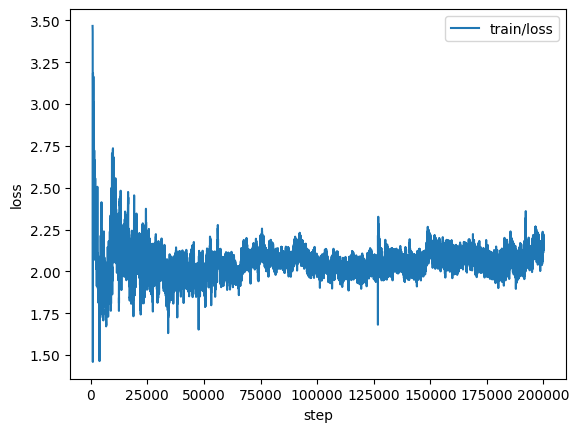

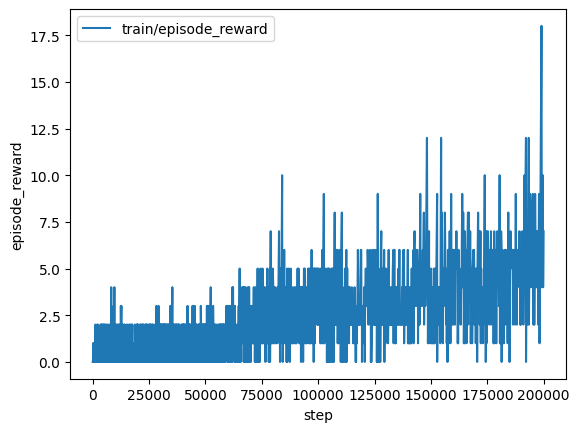

In [9]:
import matplotlib.pyplot as plt

# history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))
# metric_manager.load()
# history_dict = metric_manager.get_dataframe()

plt.figure()
ax = plt.gca()
# plt.plot(history_dict['train/loss_step'].dropna(), history_dict['train/loss'].dropna())
train_history_df.set_index('train/step')[['train/loss']].dropna().plot(kind="line", ax=ax)
plt.xlabel('step')
plt.ylabel('loss')

plt.figure()
ax = plt.gca()
# plt.plot(history_dict['train/episode_step'].dropna(), history_dict['train/episode_reward'].dropna())
train_history_df.set_index('train/step')[['train/episode_reward']].dropna().plot(kind="line", ax=ax)
plt.xlabel('step')
plt.ylabel('episode_reward')